# XGBoost robustness check: does VIX matter?
**Claim to support:** the value of VIXCLS in Elastic Net (EN) is not a quirk of a linear model. If dropping VIX also hurts XGBoost out-of-sample, the VIX result is robust.

Per ETF (XLB, XLE, XLF, XLI, XLY), expanding window, we compare `EN` vs `EN_noVIX` and `XGB` vs `XGB_noVIX`, plus `XGB_VIXonly` vs `XGB_noMacro` (does VIX alone help?).
Evaluation: **MSE** and **QLIKE** on realised variance, then **Diebold-Mariano** tests of *noVIX vs full* within each model family.

Only two files are saved to `forecasting/results/`: `e4_losses.csv` (XGBoost losses by model and ETF, including pooled results) and `e4_evaluation.csv` (all four B4 pairs: loss ratios, test statistics and p-values). Other tables and plots are displayed without separate exports.


In [29]:
import sys
from pathlib import Path

_checkout = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "models" / "research_config.py").is_file()),
    None,
)
if _checkout is None:
    raise FileNotFoundError("Start the notebook kernel from within this project checkout.")
sys.path.insert(0, str(_checkout / "models"))
from utils.paths import PROJECT_ROOT, MODELS_DIR, DATASET_DIR, FORECAST_DIR, FORECAST_RESULTS_DIR

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from pathlib import Path

# ---- CONFIG ----
from research_config import BLOCKS, TICKERS
block = BLOCKS["B4"]
# walk up from the notebook's folder until we find research_config.py (the models/ folder)
FORECAST_DIR = MODELS_DIR / "forecasting" / "forecasts"
XGB_FILE = FORECAST_DIR / "xgb_forecasts.csv"
EN_FILE  = FORECAST_DIR / "en_forecasts.csv"
RESULTS_DIR = FORECAST_RESULTS_DIR
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
# label -> model name in the CSVs
MODELS = {"EN":"en_full_macro", "EN_noVIX":"en_no_vix", "EN_noMacro":"en_no_macro",
          "XGB":"xgb_full_macro", "XGB_noVIX":"xgb_no_vix", "XGB_noMacro":"xgb_no_macro", "XGB_VIXonly":"xgb_vix_only"}
# (full, restricted) pairs: positive loss diff = first one is better
PAIRS = {"EN: full vs no VIX":("EN","EN_noVIX"), "XGB: full vs no VIX":("XGB","XGB_noVIX"),
         "XGB: VIX-only vs no macro":("XGB_VIXonly","XGB_noMacro")}


## Models used

We compare seven forecast sets, all expanding-window, per ETF (XLB, XLE, XLF, XLI, XLY), on a common sample of months.

| Label | Model name in CSV | File |
|---|---|---|
| EN | `en_full_macro` | EN |
| EN_noVIX | `en_no_vix` | EN |
| EN_noMacro | `en_no_macro` | EN |
| XGB | `xgb_full_macro` | XGB |
| XGB_noVIX | `xgb_no_vix` | XGB |
| XGB_noMacro | `xgb_no_macro` | XGB |
| XGB_VIXonly | `xgb_vix_only` | XGB |

**Excluded:** the EN models with HAR terms (`en_full_macro_har`, `en_no_macro_har`, `en_no_vix_har`) and `ols_har_no_macro`. They are not part of the VIX comparison, and the `_har` EN versions start later, which would shorten the common sample.

## Comparisons tested

| Test | Full model | Restricted model | Question |
|---|---|---|---|
| EN: full vs no VIX | EN | EN_noVIX | Does VIX improve Elastic Net? |
| XGB: full vs no VIX | XGB | XGB_noVIX | Does VIX improve XGBoost (robustness check)? |
| XGB: VIX-only vs no macro | XGB_VIXonly | XGB_noMacro | Does VIX alone add value over no macro variables? |

All three pairs are nested, so the headline tests are Clark–West on log MSE and Diebold–Mariano on QLIKE. All p-values are one-sided and use Newey–West standard errors, with the lag chosen automatically by the Andrews (1991) rule.
The exported evaluation uses `research_config.BLOCKS["B4"]`: B4.0 full vs no macro,
B4.1 full vs no VIX, B4.2 VIX-only vs no macro, and B4.3 full vs VIX-only.
The EN comparisons above remain in-notebook corroboration diagnostics.


In [18]:
f = pd.concat([pd.read_csv(XGB_FILE), pd.read_csv(EN_FILE)], ignore_index=True)
f["date"] = pd.to_datetime(f["date"])
f = f[f.model.isin(MODELS.values())].copy()           
f["model"] = f.model.map({v:k for k,v in MODELS.items()})
assert not f.duplicated(["model","etf","date"]).any()

wide = f.pivot(index=["date","etf"], columns="model", values="fc_level")[list(MODELS)].dropna()  # common sample
target = f.drop_duplicates(["date","etf"]).set_index(["date","etf"])["actual_RV"]
df = wide.join(target.rename("target"))

# NEW: log-scale forecasts and actuals, on the same common sample
logs = f.pivot(index=["date","etf"], columns="model", values="fc_log")[list(MODELS)].loc[df.index]
actual_log = f.drop_duplicates(["date","etf"]).set_index(["date","etf"])["actual_logRV"].loc[df.index]

chk = f.groupby(["date","etf"]).actual_RV.agg(["min","max"]); assert np.allclose(chk["min"], chk["max"], rtol=1e-6), "models disagree on actual_RV"
assert (df[list(MODELS)] > 0).all().all()
print(df.groupby("etf").size().rename("n").to_frame().T)
print("Common sample:", df.index.get_level_values(0).min().date(), "->", df.index.get_level_values(0).max().date())

etf  XLB  XLE  XLF  XLI  XLY
n    214  214  214  214  214
Common sample: 2008-02-29 -> 2025-11-30


## 1. Loss functions
- **MSE** = mean((RV − F)²). Squared error on the level, so a few high-vol months (2008, 2020) dominate.
- **QLIKE** = mean(RV/F − log(RV/F) − 1) (Patton 2011). Robust to noisy RV proxies and penalises under-prediction more than over-prediction, so it is the more reliable ranking here.
Lower is better for both.

In [19]:
def mse(y,F):   return (y-F)**2
def qlike(y,F): return y/F - np.log(y/F) - 1

L = {}
for name,fn in {"MSE":mse,"QLIKE":qlike}.items():
    L[name] = pd.DataFrame({m: fn(df.target, df[m]) for m in MODELS})

# NEW: MSE on log realised variance (the scale the models were trained on)
L["MSE_log"] = pd.DataFrame({m: (actual_log - logs[m])**2 for m in MODELS})

def summ(loss):
    per = loss.groupby(level="etf").mean()
    per.loc["ALL (avg)"] = per.mean()
    return per

for name in L: #for each loss it diplays the table of ave losses (lower better)
    t = summ(L[name])
    print(f"\n=== mean {name} ===")
    display(t.round(8) if name == "MSE" else t.round(4)) #MSE is small so 8 dec.

# loss reduction (%) from the full model, per ETF (positive = richer model is better)
for loss in ["MSE", "MSE_log", "QLIKE"]:
    for k,(full,restr) in PAIRS.items():
        r = 1 - L[loss][full].groupby(level="etf").mean()/L[loss][restr].groupby(level="etf").mean() ## percentage improvement from VIX
        print(f"\n{loss} | {k}: relative loss reduction")
        print((100*r).round(1).astype(str)+"%")


=== mean MSE ===


,EN,EN_noVIX,EN_noMacro,XGB,XGB_noVIX,XGB_noMacro,XGB_VIXonly
etf,,,,,,,
XLB,0.000299,0.000238,0.000064,0.000075,0.000075,0.000071,0.000073
XLE,0.000235,0.000236,0.000214,0.000249,0.000254,0.000250,0.000245
XLF,0.002061,0.001541,0.000168,0.000233,0.000244,0.000205,0.000210
XLI,0.000737,0.000072,0.000054,0.000057,0.000057,0.000056,0.000054
XLY,0.002045,0.000154,0.000037,0.000046,0.000048,0.000050,0.000043
ALL (avg),0.001075,0.000448,0.000107,0.000132,0.000136,0.000126,0.000125



=== mean QLIKE ===


,EN,EN_noVIX,EN_noMacro,XGB,XGB_noVIX,XGB_noMacro,XGB_VIXonly
etf,,,,,,,
XLB,0.2795,0.3301,0.2961,0.3919,0.4219,0.3780,0.3653
XLE,0.3573,0.3697,0.2963,0.3837,0.4051,0.3876,0.3743
XLF,0.3931,0.4611,0.4043,0.4554,0.5793,0.5030,0.4226
XLI,0.3002,0.3950,0.3389,0.3865,0.4108,0.3524,0.3145
XLY,0.2933,0.3427,0.2974,0.3434,0.3908,0.4308,0.3113
ALL (avg),0.3247,0.3797,0.3266,0.3922,0.4416,0.4104,0.3576



=== mean MSE_log ===


,EN,EN_noVIX,EN_noMacro,XGB,XGB_noVIX,XGB_noMacro,XGB_VIXonly
etf,,,,,,,
XLB,0.4203,0.4790,0.4621,0.5104,0.5598,0.5282,0.4941
XLE,0.4693,0.4815,0.4523,0.4782,0.4929,0.5081,0.4791
XLF,0.6139,0.6703,0.6653,0.6176,0.7277,0.7128,0.6279
XLI,0.4554,0.5287,0.5291,0.4933,0.5446,0.5577,0.4619
XLY,0.4918,0.5258,0.5049,0.5183,0.5583,0.6395,0.5261
ALL (avg),0.4902,0.5371,0.5228,0.5235,0.5767,0.5893,0.5178



MSE | EN: full vs no VIX: relative loss reduction
etf
XLB      -25.9%
XLE        0.3%
XLF      -33.8%
XLI     -917.3%
XLY    -1224.1%
dtype: object

MSE | XGB: full vs no VIX: relative loss reduction
etf
XLB     0.7%
XLE     2.2%
XLF     4.6%
XLI    -0.1%
XLY     3.5%
dtype: object

MSE | XGB: VIX-only vs no macro: relative loss reduction
etf
XLB    -3.1%
XLE     1.9%
XLF    -2.4%
XLI     3.1%
XLY    13.0%
dtype: object

MSE_log | EN: full vs no VIX: relative loss reduction
etf
XLB    12.3%
XLE     2.5%
XLF     8.4%
XLI    13.9%
XLY     6.5%
dtype: object

MSE_log | XGB: full vs no VIX: relative loss reduction
etf
XLB     8.8%
XLE     3.0%
XLF    15.1%
XLI     9.4%
XLY     7.2%
dtype: object

MSE_log | XGB: VIX-only vs no macro: relative loss reduction
etf
XLB     6.5%
XLE     5.7%
XLF    11.9%
XLI    17.2%
XLY    17.7%
dtype: object

QLIKE | EN: full vs no VIX: relative loss reduction
etf
XLB    15.3%
XLE     3.3%
XLF    14.7%
XLI    24.0%
XLY    14.4%
dtype: object

QLIKE | XGB: ful

## 2. Diebold-Mariano tests and Clark-West test
Loss differential d_t = L(restricted) − L(richer). Positive mean ⇒ the richer model (with VIX) is better. H0: equal predictive accuracy; one-sided H1: the VIX model is better.
Uses a Newey–West variance with the lag chosen by the Andrews (1991) rule. p-values come from the standard normal.


In [20]:
def andrews_bandwidth(x):
    x = np.asarray(x, float); n = len(x); xd = x - x.mean()
    den = float(xd[:-1] @ xd[:-1])
    rho = 0.0 if den <= 0 else float(xd[1:] @ xd[:-1]) / den
    rho = min(max(rho, -0.97), 0.97)
    a1 = 4.0 * rho**2 / ((1 - rho)**2 * (1 + rho)**2)
    return 0 if a1 <= 0 else int(min(np.floor(1.1447 * (a1 * n) ** (1/3)), n // 4))

def newey_west_lrv(x, lag):
    x = np.asarray(x, float); n = len(x); xd = x - x.mean()
    lag = max(0, min(lag, n - 1)); s = float(xd @ xd) / n
    for l in range(1, lag + 1):
        s += 2.0 * (1.0 - l / (lag + 1.0)) * float(xd[l:] @ xd[:-l]) / n
    return max(s, 1e-16)

def hac_t(d):
    d = np.asarray(d, float)
    return d.mean() / np.sqrt(newey_west_lrv(d, andrews_bandwidth(d)) / len(d))

In [21]:
def dm_test(d, lag=None, h=1):
    d = np.asarray(d, float)
    st = hac_t(d)
    return st, 1-stats.norm.cdf(st), d.mean()
            

def star(p): return "***" if p<.01 else "**" if p<.05 else "*" if p<.10 else ""

rows=[]
for loss in L:
    for k,(full,restr) in PAIRS.items():
        d_all = L[loss][restr] - L[loss][full]
        groups = {e:g.values for e,g in d_all.groupby(level="etf")}
        groups["ALL (avg across ETFs)"] = d_all.groupby(level="date").mean().values
        for e,d in groups.items():
            st,p,m = dm_test(d)
            rows.append(dict(loss=loss, family=k, etf=e, mean_diff=m, DM=st, p_one_sided=p, sig=star(p)))
dm = pd.DataFrame(rows)
display(dm.pivot_table(index="etf", columns=["loss","family"], values="DM").round(2))
display(dm.pivot_table(index="etf", columns=["loss","family"], values="p_one_sided").round(3))

loss                                 MSE                            \
family                EN: full vs no VIX XGB: VIX-only vs no macro   
etf                                                                  
ALL (avg across ETFs)              -0.91                      0.53   
XLB                                -1.13                     -0.69   
XLE                                 0.35                      1.15   
XLF                                -0.62                     -0.53   
XLI                                -1.02                      1.37   
XLY                                -0.99                      0.88   

loss                                                 MSE_log  \
family                XGB: full vs no VIX EN: full vs no VIX   
etf                                                            
ALL (avg across ETFs)                0.49               2.55   
XLB                                  0.53               3.08   
XLE                                  2.32               2.38   
XLF                                  0.29               2.05   
XLI                                 -0.05               2.08   
XLY                                  0.86               1.32   

loss                                                                 \
family                XGB: VIX-only vs no macro XGB: full vs no VIX   
etf                                                                   
ALL (avg across ETFs)                      3.86                3.21   
XLB                                        0.89                3.20   
XLE                                        1.67                1.86   
XLF                                        2.83                1.96   
XLI                                        4.13                2.52   
XLY                                        1.27                1.50   

loss                               QLIKE                            \
family                EN: full vs no VIX XGB: VIX-only vs no macro   
etf                                                                  
ALL (avg across ETFs)               1.44                      1.90   
XLB                                 1.79                      0.31   
XLE                                 1.42                      0.66   
XLF                                 0.96                      1.54   
XLI                                 1.53                      2.49   
XLY                                 1.77                      1.49   

loss                                       
family                XGB: full vs no VIX  
etf                                        
ALL (avg across ETFs)                1.79  
XLB                                  1.94  
XLE                                  1.26  
XLF                                  2.21  
XLI                                  0.66  
XLY                                  1.27

loss                                 MSE                            \
family                EN: full vs no VIX XGB: VIX-only vs no macro   
etf                                                                  
ALL (avg across ETFs)              0.818                     0.300   
XLB                                0.872                     0.756   
XLE                                0.363                     0.126   
XLF                                0.732                     0.701   
XLI                                0.846                     0.085   
XLY                                0.839                     0.188   

loss                                                 MSE_log  \
family                XGB: full vs no VIX EN: full vs no VIX   
etf                                                            
ALL (avg across ETFs)               0.310              0.005   
XLB                                 0.299              0.001   
XLE                                 0.010              0.009   
XLF                                 0.385              0.020   
XLI                                 0.519              0.019   
XLY                                 0.196              0.093   

loss                                                                 \
family                XGB: VIX-only vs no macro XGB: full vs no VIX   
etf                                                                   
ALL (avg across ETFs)                     0.000               0.001   
XLB                                       0.187               0.001   
XLE                                       0.047               0.032   
XLF                                       0.002               0.025   
XLI                                       0.000               0.006   
XLY                                       0.102               0.066   

loss                               QLIKE                            \
family                EN: full vs no VIX XGB: VIX-only vs no macro   
etf                                                                  
ALL (avg across ETFs)              0.076                     0.029   
XLB                                0.037                     0.378   
XLE                                0.078                     0.256   
XLF                                0.168                     0.061   
XLI                                0.063                     0.006   
XLY                                0.039                     0.068   

loss                                       
family                XGB: full vs no VIX  
etf                                        
ALL (avg across ETFs)               0.037  
XLB                                 0.026  
XLE                                 0.104  
XLF                                 0.014  
XLI                                 0.254  
XLY                                 0.102

In [22]:
# XGBoost vs Elastic Net, matched on the same inputs
CROSS = {"Full macro: XGB vs EN": ("XGB", "EN"),
         "No VIX: XGB vs EN":     ("XGB_noVIX", "EN_noVIX"),
         "No macro: XGB vs EN":   ("XGB_noMacro", "EN_noMacro")}

rows = []
for loss in L:
    for k,(xgb,en) in CROSS.items():
        d_all = L[loss][en] - L[loss][xgb]          # positive = XGBoost better
        groups = {e:g.values for e,g in d_all.groupby(level="etf")}
        groups["ALL (avg across ETFs)"] = d_all.groupby(level="date").mean().values
        for e,d in groups.items():
            st,_,m = dm_test(d)
            p2 = 2*(1 - stats.norm.cdf(abs(st))) if not np.isnan(st) else np.nan   # two-sided
            rows.append(dict(loss=loss, comparison=k, etf=e, mean_diff=m, DM=st, p_two_sided=p2, sig=star(p2/2)))
dm_x = pd.DataFrame(rows)
display(dm_x.pivot_table(index="etf", columns=["loss","comparison"], values="DM").round(2))
display(dm_x.pivot_table(index="etf", columns=["loss","comparison"], values="p_two_sided").round(3))

loss                                    MSE                    \
comparison            Full macro: XGB vs EN No VIX: XGB vs EN   
etf                                                             
ALL (avg across ETFs)                  1.19              1.53   
XLB                                    1.08              1.05   
XLE                                   -1.20             -1.42   
XLF                                    1.47              1.62   
XLI                                    1.02              1.00   
XLY                                    1.02              1.06   

loss                                                    MSE_log  \
comparison            No macro: XGB vs EN Full macro: XGB vs EN   
etf                                                               
ALL (avg across ETFs)               -1.38                 -1.63   
XLB                                 -1.23                 -2.23   
XLE                                 -1.16                 -0.35   
XLF                                 -1.07                 -0.10   
XLI                                 -0.78                 -1.28   
XLY                                 -1.11                 -0.88   

loss                                                         \
comparison            No VIX: XGB vs EN No macro: XGB vs EN   
etf                                                           
ALL (avg across ETFs)             -1.30               -1.67   
XLB                               -2.10               -1.65   
XLE                               -0.48               -1.23   
XLF                               -0.80               -0.76   
XLI                               -0.60               -0.83   
XLY                               -0.98               -1.35   

loss                                  QLIKE                    \
comparison            Full macro: XGB vs EN No VIX: XGB vs EN   
etf                                                             
ALL (avg across ETFs)                 -1.74             -1.74   
XLB                                   -1.88             -1.89   
XLE                                   -0.83             -0.94   
XLF                                   -1.21             -1.86   
XLI                                   -1.38             -0.36   
XLY                                   -1.19             -1.34   

loss                                       
comparison            No macro: XGB vs EN  
etf                                        
ALL (avg across ETFs)               -1.74  
XLB                                 -1.73  
XLE                                 -1.55  
XLF                                 -1.00  
XLI                                 -0.79  
XLY                                 -1.63

loss                                    MSE                    \
comparison            Full macro: XGB vs EN No VIX: XGB vs EN   
etf                                                             
ALL (avg across ETFs)                 0.235             0.127   
XLB                                   0.280             0.296   
XLE                                   0.231             0.156   
XLF                                   0.141             0.105   
XLI                                   0.306             0.316   
XLY                                   0.308             0.290   

loss                                                    MSE_log  \
comparison            No macro: XGB vs EN Full macro: XGB vs EN   
etf                                                               
ALL (avg across ETFs)               0.167                 0.104   
XLB                                 0.220                 0.026   
XLE                                 0.248                 0.725   
XLF                                 0.286                 0.918   
XLI                                 0.433                 0.201   
XLY                                 0.266                 0.381   

loss                                                         \
comparison            No VIX: XGB vs EN No macro: XGB vs EN   
etf                                                           
ALL (avg across ETFs)             0.194               0.096   
XLB                               0.036               0.098   
XLE                               0.629               0.219   
XLF                               0.425               0.444   
XLI                               0.546               0.407   
XLY                               0.329               0.177   

loss                                  QLIKE                    \
comparison            Full macro: XGB vs EN No VIX: XGB vs EN   
etf                                                             
ALL (avg across ETFs)                 0.082             0.081   
XLB                                   0.060             0.059   
XLE                                   0.406             0.347   
XLF                                   0.227             0.062   
XLI                                   0.168             0.718   
XLY                                   0.232             0.180   

loss                                       
comparison            No macro: XGB vs EN  
etf                                        
ALL (avg across ETFs)               0.083  
XLB                                 0.084  
XLE                                 0.121  
XLF                                 0.316  
XLI                                 0.427  
XLY                                 0.102

In [23]:
# Clark-West test for nested models: H1 = the richer model (with VIX) forecasts better
def cw_series(y, F_restr, F_full):
    # adjusted loss differential: restricted loss minus (full loss minus the noise adjustment)
    return (y - F_restr)**2 - ((y - F_full)**2 - (F_restr - F_full)**2)

CW_DATA = {"MSE":     (df.target, df),      # level variance
           "MSE_log": (actual_log, logs)}   # log variance

rows = []
for loss,(y,F) in CW_DATA.items():
    for k,(full,restr) in PAIRS.items():
        f_all = cw_series(y, F[restr], F[full])
        groups = {e:g.values for e,g in f_all.groupby(level="etf")}
        groups["ALL (avg across ETFs)"] = f_all.groupby(level="date").mean().values
        for e,f_ in groups.items():
            st,p,m = dm_test(f_)        # tests mean(f_) > 0 with Newey-West variance
            rows.append(dict(loss=loss, family=k, etf=e, CW=st, p_one_sided=p, sig=star(p)))
cw = pd.DataFrame(rows)
display(cw.pivot_table(index="etf", columns=["loss","family"], values="CW").round(2))
display(cw.pivot_table(index="etf", columns=["loss","family"], values="p_one_sided").round(3))

loss                                 MSE                            \
family                EN: full vs no VIX XGB: VIX-only vs no macro   
etf                                                                  
ALL (avg across ETFs)              -0.54                      2.35   
XLB                                -0.64                      0.42   
XLE                                 0.71                      1.57   
XLF                                 0.34                     -0.02   
XLI                                -0.98                      2.93   
XLY                                -0.96                      1.22   

loss                                                 MSE_log  \
family                XGB: full vs no VIX EN: full vs no VIX   
etf                                                            
ALL (avg across ETFs)                1.20               4.78   
XLB                                  1.60               4.90   
XLE                                  2.50               2.65   
XLF                                  1.09               3.68   
XLI                                  1.10               4.63   
XLY                                  1.36               4.52   

loss                                                                 
family                XGB: VIX-only vs no macro XGB: full vs no VIX  
etf                                                                  
ALL (avg across ETFs)                      5.55                4.70  
XLB                                        2.82                4.68  
XLE                                        2.91                2.41  
XLF                                        4.44                2.31  
XLI                                        5.44                4.21  
XLY                                        1.72                2.88

loss                                 MSE                            \
family                EN: full vs no VIX XGB: VIX-only vs no macro   
etf                                                                  
ALL (avg across ETFs)              0.704                     0.009   
XLB                                0.739                     0.339   
XLE                                0.239                     0.058   
XLF                                0.365                     0.509   
XLI                                0.836                     0.002   
XLY                                0.831                     0.112   

loss                                                 MSE_log  \
family                XGB: full vs no VIX EN: full vs no VIX   
etf                                                            
ALL (avg across ETFs)               0.115              0.000   
XLB                                 0.055              0.000   
XLE                                 0.006              0.004   
XLF                                 0.138              0.000   
XLI                                 0.136              0.000   
XLY                                 0.086              0.000   

loss                                                                 
family                XGB: VIX-only vs no macro XGB: full vs no VIX  
etf                                                                  
ALL (avg across ETFs)                     0.000               0.000  
XLB                                       0.002               0.000  
XLE                                       0.002               0.008  
XLF                                       0.000               0.010  
XLI                                       0.000               0.000  
XLY                                       0.043               0.002

In [24]:
LOSS_MAP = {"QLIKE": "QLIKE", "MSE_log": "MSE_log", "MSE": "MSE_level"}

parts = []
for m, name in MODELS.items():
    t = pd.DataFrame({new: L[old][m] for old, new in LOSS_MAP.items()})
    g = t.groupby(level="etf").mean().reset_index().rename(columns={"etf": "ETF"})
    g = pd.concat([g, t.mean().to_frame().T.assign(ETF="pooled")], ignore_index=True)
    g.insert(0, "model", name); parts.append(g)
vix_losses = pd.concat(parts, ignore_index=True)
vix_losses[vix_losses["model"].isin(block["models"])].to_csv(RESULTS_DIR / "e4_losses.csv", index=False)

li = vix_losses.set_index(["model", "ETF"])
etfs = sorted(df.index.get_level_values("etf").unique())
rows = []
labels = {name: label for label, name in MODELS.items()}
for pair_id, model_a, model_b, _ in block["pairs"]:
    a, b = labels[model_a], labels[model_b]
    cw_t_all = cw_series(actual_log, logs[b], logs[a])      # Clark-West; positive favours a
    dm_t_all = L["QLIKE"][b] - L["QLIKE"][a]                # positive favours a
    for etf in ["pooled"] + etfs:
        if etf == "pooled": cw_x, dm_x_ = cw_t_all.groupby(level="date").mean(), dm_t_all.groupby(level="date").mean()
        else:               cw_x, dm_x_ = cw_t_all.xs(etf, level="etf"), dm_t_all.xs(etf, level="etf")
        for loss, test, x in [("QLIKE", "DM", dm_x_), ("MSE_log", "Clark-West", cw_x)]:
            t_ = hac_t(x)
            rows.append({"pair": pair_id, "a": MODELS[a], "b": MODELS[b], "ETF": etf, "loss": loss, "test": test,
                         "loss_ratio": li.loc[(MODELS[a], etf), loss] / li.loc[(MODELS[b], etf), loss],
                         "gain_t": t_, "p_value": float(1 - stats.norm.cdf(t_))})
vix_tests = pd.DataFrame(rows)
vix_tests["pct_change"] = (vix_tests["loss_ratio"] - 1) * 100
vix_tests.to_csv(RESULTS_DIR / "e4_evaluation.csv", index=False)

def fmt_p(p): return "<0.001" if p < 0.001 else f"{p:.3f}"
print("Pooled (Clark-West on log MSE = primary; QLIKE = supporting):")
display(vix_tests[vix_tests.ETF == "pooled"].drop(columns="ETF").round(4).reset_index(drop=True))

for loss, test in [("MSE_log", "Clark-West"), ("QLIKE", "DM")]:
    s = vix_tests[vix_tests.loss == loss].copy()
    s["cell"] = [f"{r:.2f} ({fmt_p(p)})" for r, p in zip(s.loss_ratio, s.p_value)]
    s["row"] = s.pair + ": " + s.a + " vs " + s.b
    print(f"\n{loss}: loss ratio (one-sided p), {test}")
    display(s.pivot(index="row", columns="ETF", values="cell")[etfs + ["pooled"]].rename_axis(None))

Pooled (Clark-West on log MSE = primary; QLIKE = supporting):


,pair,a,b,loss,test,loss_ratio,gain_t,p_value
0,P1,en_full_macro,en_no_vix,QLIKE,DM,0.8551,1.4351,0.0756
1,P1,en_full_macro,en_no_vix,MSE_log,Clark-West,0.9126,4.7792,0.0000
2,P2,xgb_full_macro,xgb_no_vix,QLIKE,DM,0.8881,1.7866,0.0370
3,P2,xgb_full_macro,xgb_no_vix,MSE_log,Clark-West,0.9079,4.7014,0.0000
4,P3,xgb_vix_only,xgb_no_macro,QLIKE,DM,0.8714,1.8963,0.0290
5,P3,xgb_vix_only,xgb_no_macro,MSE_log,Clark-West,0.8788,5.5460,0.0000



MSE_log: loss ratio (one-sided p), Clark-West


ETF,XLB,XLE,XLF,XLI,XLY,pooled
P1: en_full_macro vs en_no_vix,0.88 (<0.001),0.97 (0.004),0.92 (<0.001),0.86 (<0.001),0.94 (<0.001),0.91 (<0.001)
P2: xgb_full_macro vs xgb_no_vix,0.91 (<0.001),0.97 (0.008),0.85 (0.010),0.91 (<0.001),0.93 (0.002),0.91 (<0.001)
P3: xgb_vix_only vs xgb_no_macro,0.94 (0.002),0.94 (0.002),0.88 (<0.001),0.83 (<0.001),0.82 (0.043),0.88 (<0.001)



QLIKE: loss ratio (one-sided p), DM


ETF,XLB,XLE,XLF,XLI,XLY,pooled
P1: en_full_macro vs en_no_vix,0.85 (0.037),0.97 (0.078),0.85 (0.168),0.76 (0.063),0.86 (0.039),0.86 (0.076)
P2: xgb_full_macro vs xgb_no_vix,0.93 (0.026),0.95 (0.104),0.79 (0.014),0.94 (0.254),0.88 (0.102),0.89 (0.037)
P3: xgb_vix_only vs xgb_no_macro,0.97 (0.378),0.97 (0.256),0.84 (0.061),0.89 (0.006),0.72 (0.068),0.87 (0.029)


## 3. Cumulative loss differential (does the VIX gain build up steadily or come from a few episodes?)

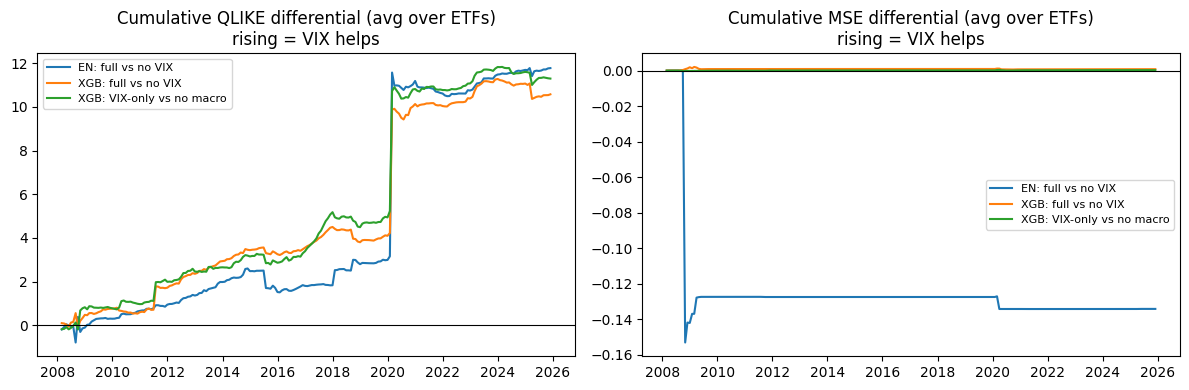

In [28]:
fig, ax = plt.subplots(1,2, figsize=(12,4), sharex=True)
for a,loss in zip(ax,["QLIKE","MSE"]):
    for k,(full,restr) in PAIRS.items():
        d = (L[loss][restr]-L[loss][full]).groupby(level="date").mean()
        a.plot(d.cumsum(), label=k)
    a.axhline(0,color="k",lw=.8); a.set_title(f"Cumulative {loss} differential (avg over ETFs)\nrising = VIX helps"); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 4. Results interpretation (auto-generated from the numbers above)

In [26]:
def verdict(k, loss):
    r = dm[(dm.loss==loss)&(dm.family==k)]
    allrow = r[r.etf.str.startswith("ALL")].iloc[0]
    e = r[~r.etf.str.startswith("ALL")]
    return allrow, (e.mean_diff>0).sum(), (e.p_one_sided<.10).sum(), len(e)

for loss in ["QLIKE","MSE"]:
    for k in PAIRS:
        a,npos,nsig,n = verdict(k,loss)
        direction = "improves" if a.mean_diff>0 else "does NOT improve"
        print(f"- {loss} | {k}: VIX {direction} accuracy on average (DM={a.DM:.2f}, one-sided p={a.p_one_sided:.3f}{a.sig}); "
              f"better in {npos}/{n} ETFs, significantly (10%) in {nsig}/{n}.")

p = cw[cw.loss.eq("MSE_log") & cw.etf.str.startswith("ALL")].set_index("family")["p_one_sided"]
ok = p["EN: full vs no VIX"] < .05 and p["XGB: full vs no VIX"] < .05
print("\nCONCLUSION (Clark-West on log MSE):",
      "XGBoost corroborates EN: VIX adds significant out-of-sample value in both model families (robust)." if ok else
      "Evidence is not significant in at least one family: report as supportive, not conclusive.")

- QLIKE | EN: full vs no VIX: VIX improves accuracy on average (DM=1.44, one-sided p=0.076*); better in 5/5 ETFs, significantly (10%) in 4/5.
- QLIKE | XGB: full vs no VIX: VIX improves accuracy on average (DM=1.79, one-sided p=0.037**); better in 5/5 ETFs, significantly (10%) in 2/5.
- QLIKE | XGB: VIX-only vs no macro: VIX improves accuracy on average (DM=1.90, one-sided p=0.029**); better in 5/5 ETFs, significantly (10%) in 3/5.
- MSE | EN: full vs no VIX: VIX does NOT improve accuracy on average (DM=-0.91, one-sided p=0.818); better in 1/5 ETFs, significantly (10%) in 0/5.
- MSE | XGB: full vs no VIX: VIX improves accuracy on average (DM=0.49, one-sided p=0.310); better in 4/5 ETFs, significantly (10%) in 1/5.
- MSE | XGB: VIX-only vs no macro: VIX improves accuracy on average (DM=0.53, one-sided p=0.300); better in 3/5 ETFs, significantly (10%) in 1/5.

CONCLUSION (Clark-West on log MSE): XGBoost corroborates EN: VIX adds significant out-of-sample value in both model families (rob

## 5. Percentage change in loss by comparison

% change in mean loss = (loss of richer model / loss of restricted model − 1) × 100. **Negative = the richer model is better** (lower loss).

- **Pooled summary** (the slide table): five XGBoost comparisons on log MSE and QLIKE, pooled over the five ETFs.
- **By ticker:** the same comparisons for XLB, XLE, XLF, XLI and XLY.
- Displayed in this notebook; the percentage-change tables are not exported separately.

Comparisons:
1. Full (macro + VIX) vs no macro
2. Add VIX to a no-macro model
3. Add other ten to VIX
4. Add VIX to the other ten
5. Other ten alone vs no macro

In [27]:
# % change in mean loss = (loss of richer model / loss of restricted model - 1) * 100
# Negative = richer model is better.
XGB_COMPARISONS = [
    ("Full (macro + VIX) vs no macro", "XGB",         "XGB_noMacro"),
    ("Add VIX to a no-macro model",    "XGB_VIXonly", "XGB_noMacro"),
    ("Add other ten to VIX",           "XGB",         "XGB_VIXonly"),
    ("Add VIX to the other ten",       "XGB",         "XGB_noVIX"),
    ("Other ten alone vs no macro",    "XGB_noVIX",   "XGB_noMacro"),
]
fmt = lambda x: f"{x:+.1f}%".replace("-", "\u2212")

def mean_loss(loss, model):
    per_etf = L[loss][model].groupby(level="etf").mean()
    per_etf["Pooled"] = L[loss][model].mean()          # pooled = average over all ETF-months
    return per_etf

pct_rows = []
for name, a, b in XGB_COMPARISONS:
    for loss in ["MSE_log", "QLIKE"]:
        pct = (mean_loss(loss, a) / mean_loss(loss, b) - 1) * 100
        pct_rows.append(pd.DataFrame({"comparison": name, "loss": loss,
                                      "ETF": pct.index, "pct_change": pct.values}))
xgb_pct = pd.concat(pct_rows, ignore_index=True)

# 1) Pooled summary table for the slide
summary = (xgb_pct[xgb_pct.ETF == "Pooled"]
           .pivot(index="comparison", columns="loss", values="pct_change")
           .loc[[c[0] for c in XGB_COMPARISONS], ["MSE_log", "QLIKE"]]
           .rename(columns={"MSE_log": "Log MSE"}))
print("XGBoost: % change in pooled loss (negative = richer model better)")
display(summary.map(fmt).rename_axis(None))     # use .applymap on older pandas

# 2) Same thing per ticker
for loss in ["MSE_log", "QLIKE"]:
    t = (xgb_pct[xgb_pct.loss == loss]
         .pivot(index="comparison", columns="ETF", values="pct_change")
         .loc[[c[0] for c in XGB_COMPARISONS], etfs + ["Pooled"]])
    print(f"\n{loss}: % change in loss by ticker")
    display(t.map(fmt).rename_axis(None))

XGBoost: % change in pooled loss (negative = richer model better)


loss,Log MSE,QLIKE
Full (macro + VIX) vs no macro,−11.2%,−4.4%
Add VIX to a no-macro model,−12.1%,−12.9%
Add other ten to VIX,+1.1%,+9.7%
Add VIX to the other ten,−9.2%,−11.2%
Other ten alone vs no macro,−2.1%,+7.6%



MSE_log: % change in loss by ticker


ETF,XLB,XLE,XLF,XLI,XLY,Pooled
Full (macro + VIX) vs no macro,−3.4%,−5.9%,−13.4%,−11.5%,−19.0%,−11.2%
Add VIX to a no-macro model,−6.5%,−5.7%,−11.9%,−17.2%,−17.7%,−12.1%
Add other ten to VIX,+3.3%,−0.2%,−1.6%,+6.8%,−1.5%,+1.1%
Add VIX to the other ten,−8.8%,−3.0%,−15.1%,−9.4%,−7.2%,−9.2%
Other ten alone vs no macro,+6.0%,−3.0%,+2.1%,−2.4%,−12.7%,−2.1%



QLIKE: % change in loss by ticker


ETF,XLB,XLE,XLF,XLI,XLY,Pooled
Full (macro + VIX) vs no macro,+3.7%,−1.0%,−9.5%,+9.7%,−20.3%,−4.4%
Add VIX to a no-macro model,−3.4%,−3.4%,−16.0%,−10.8%,−27.8%,−12.9%
Add other ten to VIX,+7.3%,+2.5%,+7.7%,+22.9%,+10.3%,+9.7%
Add VIX to the other ten,−7.1%,−5.3%,−21.4%,−5.9%,−12.1%,−11.2%
Other ten alone vs no macro,+11.6%,+4.5%,+15.2%,+16.6%,−9.3%,+7.6%
